# Les déserts de carburant en France

*Projet réalisé par Aurélien Quisefit et François Ndoumbe*

## Introduction

### Contexte

En dehors des grandes villes, la voiture est quasiment le seul moyen de se déplacer : aller travailler, faire ses courses ou amener ses enfants à l'école suppose de pouvoir faire le plein. Or, le réseau de stations-service s'est fortement réduit depuis plusieurs décennies. Les petites stations indépendantes ferment faute de rentabilité, et l'offre se concentre dans les grandes surfaces et le long des axes principaux. Aujourd'hui, environ 10 000 stations publient leurs prix en France métropolitaine, pour près de 35 000 communes.

En outre, le prix des carburants est devenu un sujet politique sensible, autour de 2 €/L pour le gazole. On pense ici aux manifestations des gilets jaunes. Ce sujet est d'ailleurs revenu le mois dernier dans les manifestations, rejoignant le mouvement lycéen. Pour les ménages ruraux, il pèse d'autant plus que les distances parcourues sont longues.

On appelle ici **« désert de carburant »** une commune éloignée de toute station-service. Ses habitants doivent faire un détour pour faire le plein et ont peu de choix entre les stations.

### Problématique

**Les habitants des déserts de carburant sont-ils désavantagés, et pourquoi ces déserts existent-ils ?**

On teste en particulier deux hypothèses :
1. **Où sont les déserts ?** Ils s'expliqueraient par la faible densité de population et par le relief.
2. **Les habitants paient-ils plus cher ?** Avec peu de concurrence à proximité, les stations isolées pourraient pratiquer des prix plus élevés.

### Données

- **Le flux officiel des prix des carburants** (donnees.roulez-eco.fr) : les stations-service ont l'obligation légale de déclarer leurs prix. Le flux donne la position de chaque station et ses prix par carburant.
- **L'API Géo** (geo.api.gouv.fr) : la position, la population et la superficie de chaque commune.

Ces données sont *instantanées* : en relançant le notebook un autre jour, les chiffres varient légèrement, mais les conclusions restent les mêmes.

### Plan

1. Collecte et nettoyage des données sur les stations et les prix
2. Calcul de la distance entre chaque commune et la station la plus proche
3. Définition d'un seuil de désert et repérage sur le territoire
4. Les habitants des déserts paient-ils plus cher ?
5. Les déserts selon la densité et le département
6. Conclusion et limites

On commence par importer les bibliothèques importantes. Puis on va chercher les données sur Internet (source : donnees.roulez-eco.fr). Elles sont disponibles car les stations-service ont l'obligation légale de publier leurs données. Par contre, les données sont instantanées. On ne fait pas de série temporelle donc le résultat qu'on obtiendrait sur nos données dans 1 semaine ne sera plus exactement le même. On vérifie que l'importation s'est bien passée puis on ouvre le zip et on lit le XML qui est dedans. On obtient 9827 observations de stations-service. 

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

import fonctions

In [2]:
df_stations, df_prix = fonctions.telecharger_stations_et_prix()
print(len(df_stations), "stations et", len(df_prix), "prix")

9827 stations et 33199 prix


On sépare le XML en deux tableaux, un pour les stations (position, etc.) et un autre pour les prix. Cela nous permet d'éviter les répétitions de lignes.

In [3]:
df_prix.head()

,id,carburant,valeur,maj
0,56580001,Gazole,2.109,2026-11-12 06:55:20
1,56580001,SP95,2.009,2026-11-12 06:55:20
2,56580001,SP98,2.049,2026-11-12 06:55:21
3,89100001,Gazole,2.099,2026-11-23 14:35:41
4,89100001,E85,0.869,2026-11-10 09:49:38


On normalise les degrés de longitude et de latitude pour avoir les bonnes conventions de valeurs et on ne sélectionne que les stations en métropole (en réalité, on n'exclut aucune station donc toutes nos stations l'étaient déjà). Ensuite, on exclut les valeurs aberrantes (il n'y en avait pas) et on enlève les prix périmés (on considère qu'un prix non actualisé depuis plus de 7 jours n'est plus pratiqué la plupart du temps). 

In [4]:
df_stations["latitude"] = pd.to_numeric(df_stations["latitude"], errors="coerce") / 100_000
df_stations["longitude"] = pd.to_numeric(df_stations["longitude"], errors="coerce") / 100_000
df_stations["departement"] = df_stations["cp"].str[:2]

# On garde la France métropolitaine (Corse comprise) grâce à un rectangle de coordonnées
en_metropole = (
    df_stations["latitude"].between(41, 51.5)
    & df_stations["longitude"].between(-5.5, 10)
)
print("Stations hors métropole ou sans coordonnées :", (~en_metropole).sum())
df_stations = df_stations[en_metropole].copy()
print("Stations conservées :", len(df_stations))

Stations hors métropole ou sans coordonnées : 0
Stations conservées : 9827


In [5]:
df_prix["valeur"] = pd.to_numeric(df_prix["valeur"], errors="coerce")
df_prix["maj"] = pd.to_datetime(df_prix["maj"], errors="coerce")

prix_plausible = df_prix["valeur"].between(0.5, 3.5)
date_reference = df_prix["maj"].max()
prix_recent = df_prix["maj"] >= date_reference - pd.Timedelta(days=7)

print("Prix hors de [0,50 ; 3,50] €/L :", (~prix_plausible).sum())
print("Prix de plus de 7 jours :", (~prix_recent).sum())

df_prix = df_prix[prix_plausible & prix_recent & df_prix["id"].isin(df_stations["id"])].copy()
print("Prix conservés :", len(df_prix))
df_prix.groupby("carburant")["valeur"].describe()

Prix hors de [0,50 ; 3,50] €/L : 0
Prix de plus de 7 jours : 6025
Prix conservés : 27174


,count,mean,std,min,25%,50%,75%,max
carburant,,,,,,,,
E10,6821.0,1.946094,0.074878,1.339,1.898,1.931,1.989,2.919
E85,2601.0,0.896123,0.071923,0.659,0.858,0.885,0.919,2.019
GPLc,897.0,1.087099,0.073642,0.866,1.023,1.088,1.149,1.394
Gazole,8257.0,2.104463,0.088898,1.833,2.029,2.087,2.177,2.530
SP95,2065.0,2.007212,0.070212,1.858,1.965,1.990,2.029,2.380
SP98,6533.0,2.045854,0.082405,1.862,1.990,2.012,2.079,2.529


On importe maintenant les communes avec leur position, leur superficie et leur population car on a besoin de savoir où habitent les gens pour savoir s'ils sont plus ou moins loin des stations.

In [6]:
df_communes = fonctions.telecharger_communes()
print(df_communes.shape)
df_communes.head()

(34969, 7)


,code,nom,population,surface,codeDepartement,centre.type,centre.coordinates
0,01001,L'Abergement-Clémenciat,860.0,1564.50,01,Point,"[4.9306, 46.1517]"
1,01002,L'Abergement-de-Varey,270.0,919.01,01,Point,"[5.4247, 46.0071]"
2,01004,Ambérieu-en-Bugey,15934.0,2454.80,01,Point,"[5.3706, 45.9575]"
3,01005,Ambérieux-en-Dombes,1906.0,1603.97,01,Point,"[4.9119, 45.9992]"
4,01006,Ambléon,115.0,604.01,01,Point,"[5.5928, 45.7483]"


On sépare en deux colonnes la longitude et la latitude. On convertit la surface en km². On retire les outre-mer (le tableau Prix ne les comprenait pas) et les communes sans population. On remarque que la commune médiane a 456 habitants et qu'on a 34746 communes pour 9827 stations.

In [7]:
df_communes["longitude"] = df_communes["centre.coordinates"].str[0]
df_communes["latitude"] = df_communes["centre.coordinates"].str[1]

df_communes["surface_km2"] = df_communes["surface"] / 100
df_communes["densite"] = df_communes["population"] / df_communes["surface_km2"]

en_metropole = (
    df_communes["latitude"].between(41, 51.5)
    & df_communes["longitude"].between(-5.5, 10)
)
avec_population = df_communes["population"].notna()
print("Communes retirées :", (~(en_metropole & avec_population)).sum())

df_communes = df_communes[en_metropole & avec_population].copy()
print("Communes conservées :", len(df_communes))
df_communes[["nom", "population", "surface_km2", "densite"]].describe()

Communes retirées : 223
Communes conservées : 34746


,population,surface_km2,densite
count,3.474600e+04,34746.000000,34746.000000
mean,1.904271e+03,15.799415,165.933598
std,1.490933e+04,17.356149,750.041526
min,0.000000e+00,0.028400,0.000000
25%,1.970000e+02,6.520025,18.199153
50%,4.560000e+02,10.978000,40.310795
75%,1.163000e+03,19.014775,96.828126
max,2.103778e+06,756.780100,28187.274910


On mesure la distance à vol d'oiseau faute de calculateur d'itinéraires (malheureusement, cela sous-estime le trajet réel, surtout en montagne). Pour éviter de comparer chaque commune à chaque station (≈ 341 millions de calculs), on utilise un BallTree, qui regroupe les stations par zones et élimine d'emblée les plus lointaines. On trouve que la distance médiane est de 4,6 km. Les extrêmes sont cohérents. Sentein et Antras sont dans les montagnes. Ouessant et Hœdic sont des îles. Ces dernières posent une question. Selon toute vraisemblance, il n'y a pas de stations sur ces îles officiellement enregistrées. Peut-être que le carburant arrive par bateau.

In [8]:
df_communes["distance_station_km"], df_communes["station_proche_id"] = (
    fonctions.distance_plus_proche(df_communes, df_stations)
)
print(df_communes["distance_station_km"].describe())

count    34746.000000
mean         4.975027
std          2.979419
min          0.013784
25%          2.745302
50%          4.653100
75%          6.736492
max         27.167184
Name: distance_station_km, dtype: float64


In [9]:
print("Communes les plus éloignées :")
print(
    df_communes
    .nlargest(10, "distance_station_km")[["nom", "codeDepartement", "population", "distance_station_km"]]
)

Communes les plus éloignées :
                        nom codeDepartement  population  distance_station_km
10377              Ouessant              29       860.0            27.167184
3086                Sentein              09       175.0            23.150883
20542                 Hœdic              56       104.0            21.756735
6869       Gurgy-le-Château              21        45.0            21.514817
2819                 Antras              09        74.0            21.174219
6818   Faverolles-lès-Lucey              21        29.0            20.695044
6689               Chambain              21        36.0            20.628464
6683             Buxerolles              21        34.0            20.313196
6868         Gurgy-la-Ville              21        26.0            20.186046
6914                  Lucey              21        56.0            19.996444


On choisit a priori un seuil de 10 km pour le désert de carburant. On vérifie ensuite que ce seuil correspond à un quantile cohérent. En effet, seules 6 % des communes sont à plus de 10 km à vol d'oiseau d'une station, et seulement 1 % des habitants sont concernés car ces communes sont peu peuplées. Certes, cela ne représente que 1 % des habitants, mais cela fait quand même 636 000 personnes.

In [10]:
SEUIL_DESERT_KM = 10

df_communes["est_desert"] = df_communes["distance_station_km"] > SEUIL_DESERT_KM

nb_communes = df_communes["est_desert"].sum()
part_communes = 100 * df_communes["est_desert"].mean()
pop_desert = df_communes.loc[df_communes["est_desert"], "population"].sum()
part_pop = 100 * pop_desert / df_communes["population"].sum()

print(f"Communes en désert : {nb_communes} ({part_communes:.1f} %)")
print(f"Habitants concernés : {pop_desert:,.0f} ({part_pop:.1f} %)")

print("\nDistribution des distances :")
print(df_communes["distance_station_km"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

Communes en désert : 2081 (6.0 %)
Habitants concernés : 636,124 (1.0 %)

Distribution des distances :
0.50     4.653100
0.75     6.736492
0.90     8.897535
0.95    10.361400
0.99    13.641910
Name: distance_station_km, dtype: float64


Ce seuil semble plutôt bien choisi.

In [11]:
for seuil in [5, 10, 15]:
    masque = df_communes["distance_station_km"] > seuil
    print(f"{seuil} km : {masque.sum()} communes, {df_communes.loc[masque, 'population'].sum():,.0f} habitants")

5 km : 15729 communes, 7,132,712 habitants
10 km : 2081 communes, 636,124 habitants
15 km : 171 communes, 27,503 habitants


On importe Seaborn pour obtenir un histogramme de la distribution des communes selon leur distance à une station. On trouve un mode à 5 km, et la plupart des communes sont à moins de 7 km d'une station. La distribution est asymétrique, ce qui est cohérent.

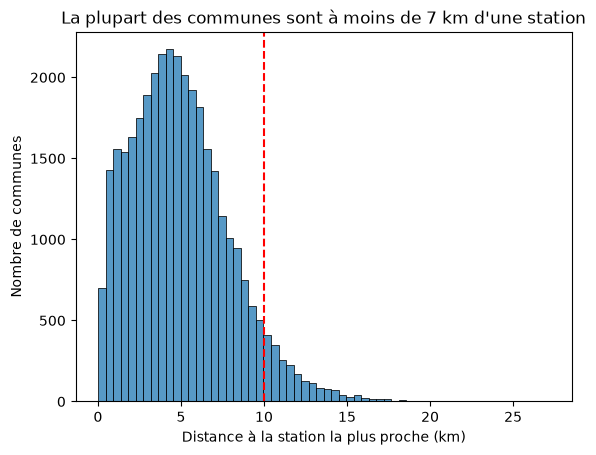

In [12]:
ax = sns.histplot(df_communes, x="distance_station_km", bins=60)
ax.axvline(SEUIL_DESERT_KM, color="red", linestyle="--")
ax.set(xlabel="Distance à la station la plus proche (km)",
       ylabel="Nombre de communes",
              title="La plupart des communes sont à moins de 7 km d'une station");

Seaborn n'a pas été performant pour construire une carte avec des couleurs continues. On réutilise donc matplotlib (importé au début). Chaque point est une commune dont l'intensité de la couleur révèle sa distance à une station. On trouve un résultat cohérent : les zones rouges coïncident avec les reliefs (Alpes, Pyrénées, Massif central, etc.). On voit aussi des zones rouges dans des plaines, comme le Châtillonnais, qui correspondent à des zones de très faible densité. On conclut que les déserts viennent principalement de deux raisons : la géographie inadaptée et la faible densité (ou les deux).

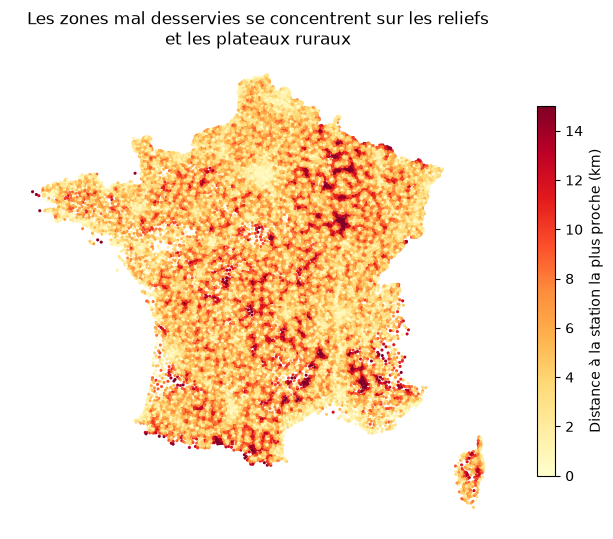

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))

nuage = ax.scatter(
    df_communes["longitude"], df_communes["latitude"],
    c=df_communes["distance_station_km"],
    cmap="YlOrRd", s=1.5, vmin=0, vmax=15,
)
fig.colorbar(nuage, ax=ax, label="Distance à la station la plus proche (km)", shrink=0.6)

ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_axis_off()
ax.set_title("Les zones mal desservies se concentrent sur les reliefs\net les plateaux ruraux")
plt.show()

On définit le prix moyen d'une station en choisissant le gazole car il est le plus répandu. On associe à chaque commune le prix du gazole dans la station la plus proche. La proportion de communes sans prix est la même pour les déserts que pour les autres donc il n'y a pas de biais de sélection. Enfin, on trouve que l'écart est de 1,2 centime par litre. Autrement dit, l'hypothèse qui avait motivé notre projet, à savoir que les habitants des déserts de carburant sont piégés et paient plus cher, semble fausse. 

In [14]:
prix_moyen_station = (
    df_prix[df_prix["carburant"] == "Gazole"]
    .groupby("id")["valeur"]
    .mean()
)

df_communes["prix_gazole"] = df_communes["station_proche_id"].map(prix_moyen_station)

print("Communes sans prix gazole :", df_communes["prix_gazole"].isna().sum())
print(df_communes.groupby("est_desert")["prix_gazole"].agg(["count", "mean", "median"]))

Communes sans prix gazole : 6888
            count      mean  median
est_desert                         
False       26242  2.110916   2.089
True         1616  2.123169   2.099


Les boîtes se chevauchent presque parfaitement. L'écart est négligeable économiquement.

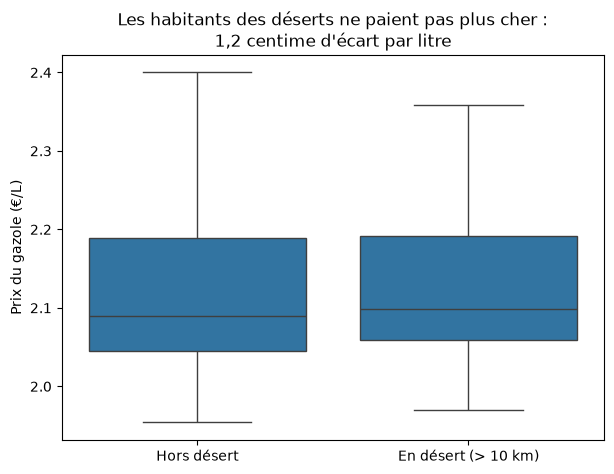

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=df_communes.dropna(subset=["prix_gazole"]),
    x="est_desert", y="prix_gazole", ax=ax, showfliers=False,
)
ax.set_xticks([0, 1], ["Hors désert", "En désert (> 10 km)"])
ax.set(xlabel="", ylabel="Prix du gazole (€/L)",
       title="Les habitants des déserts ne paient pas plus cher :\n1,2 centime d'écart par litre")
plt.show()

La médiane décroît de manière régulière avec la densité. On trouve un facteur six entre la distance médiane d'une densité inférieure à 6 et une densité supérieure à 300 habitants par km².

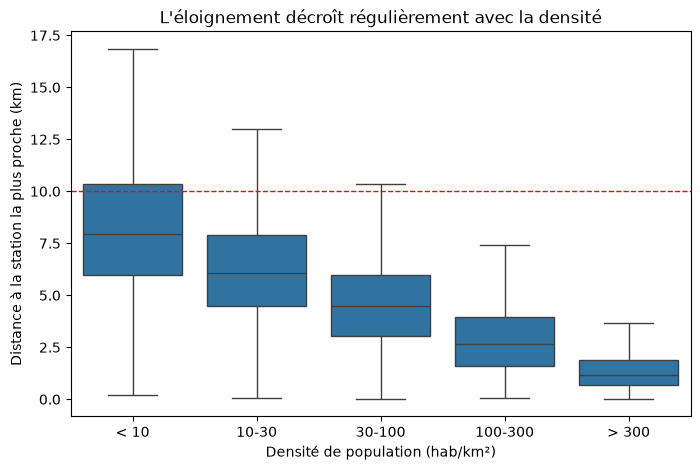

In [16]:
df_communes["classe_densite"] = pd.cut(
    df_communes["densite"],
    bins=[0, 10, 30, 100, 300, float("inf")],
    labels=["< 10", "10-30", "30-100", "100-300", "> 300"],
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_communes, x="classe_densite", y="distance_station_km", ax=ax, showfliers=False)
ax.axhline(SEUIL_DESERT_KM, color="red", linestyle="--", linewidth=1)
ax.set(xlabel="Densité de population (hab/km²)", ylabel="Distance à la station la plus proche (km)",
       title="L'éloignement décroît régulièrement avec la densité")
plt.show()

In [17]:
par_departement = (
    df_communes
    .groupby("codeDepartement")
    .agg(
        distance_mediane=("distance_station_km", "median"),
        part_desert=("est_desert", "mean"),
        population=("population", "sum"),
        nb_communes=("code", "size"),
    )
    .sort_values("distance_mediane", ascending=False)
)
par_departement["part_desert"] = (100 * par_departement["part_desert"]).round(1)

print("Les 10 départements les plus éloignés :")
print(par_departement.head(10))
print("\nLes 5 mieux desservis :")
print(par_departement.tail(5))

Les 10 départements les plus éloignés :
                 distance_mediane  part_desert  population  nb_communes
codeDepartement                                                        
55                       6.839669         20.4    180290.0          499
36                       6.748798         12.9    216069.0          241
52                       6.571291         19.7    168331.0          426
09                       6.562421         15.1    155722.0          325
23                       6.554302         18.8    115527.0          255
15                       6.335119         17.2    144196.0          250
48                       6.288670         21.1     76486.0          152
32                       6.213430          8.7    192645.0          458
2B                       6.208393         15.7    187180.0          236
03                       6.193944         11.0    333298.0          317

Les 5 mieux desservis :
                 distance_mediane  part_desert  population  nb_communes

Sans surprise, la diagonale du vide apparaît le plus dans les départements les plus éloignés, mais d'autres aussi comme l'Ariège ou la Lozère. On trouve notamment un facteur 14 entre la Meuse et Paris. La Lozère montre la plus forte part de communes en désert (21,1 %) sans avoir la distance médiane la plus élevée. Autrement dit, sa distribution est plus contrastée que celle des départements de la diagonale du vide. Le relief y crée des ruptures d'accès localisées, tandis que le dépeuplement produit un éloignement plus uniforme.

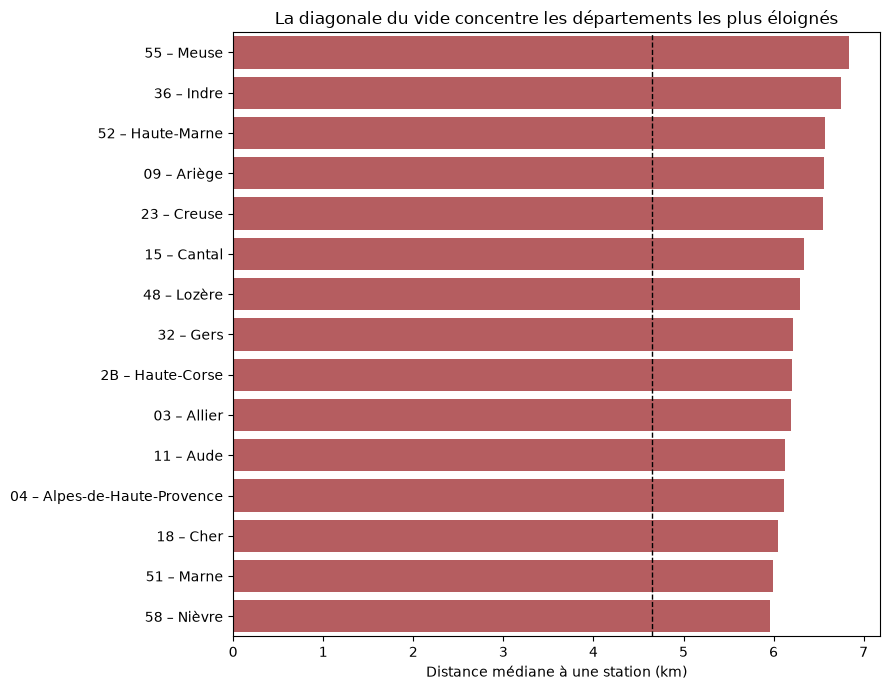

In [18]:
noms_departements = pd.json_normalize(
    requests.get("https://geo.api.gouv.fr/departements?fields=code,nom", timeout=60).json()
).set_index("code")["nom"]

top15 = par_departement.head(15).copy()
top15["libelle"] = top15.index + " – " + top15.index.map(noms_departements)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top15["distance_mediane"], y=top15["libelle"], ax=ax, color="#C44E52")

mediane_nationale = df_communes["distance_station_km"].median()
ax.axvline(mediane_nationale, color="black", linestyle="--", linewidth=1)
ax.annotate(
    "Médiane nationale", xy=(mediane_nationale, 14.6),
    xytext=(4, 0), textcoords="offset points", fontsize=9, va="center",
)

ax.set(xlabel="Distance médiane à une station (km)", ylabel="",
       title="La diagonale du vide concentre les départements les plus éloignés")
fig.tight_layout()
plt.show()

## 6. Conclusion et limites

### Principaux résultats

**1. Les déserts de carburant existent, mais concernent peu d'habitants.**
Avec un seuil de 10 km à vol d'oiseau, environ 6 % des communes de métropole sont en désert de carburant. Comme ces communes sont les moins peuplées, cela ne représente qu'environ 1 % de la population. Cela représente malgré tout plus de 600 000 personnes. Pour la plupart des Français, la station la plus proche se trouve à moins de 5 km (distance médiane d'environ 4,6 km).

**2. Les déserts s'expliquent par la faible densité et par le relief.**
La distance à la station la plus proche diminue régulièrement quand la densité de population augmente. Sur la carte, les zones mal desservies correspondent aux massifs montagneux (Pyrénées, Alpes, Massif central) et aux plateaux ruraux peu peuplés de la « diagonale du vide » (Meuse, Haute-Marne, Creuse, Indre…). Les deux mécanismes sont toutefois distincts : le dépeuplement produit un éloignement général dans tout le département, alors que le relief crée des poches isolées, comme en Lozère, qui a la plus forte part de communes en désert sans avoir la distance médiane la plus élevée.

**3. Les habitants des déserts ne paient pas plus cher leur carburant.**
L'hypothèse qui a motivé ce projet est contredite. L'écart de prix du gazole entre la station la plus proche des communes en désert et celle des autres communes n'est que d'environ 1 centime par litre, soit environ 0,60 € pour un plein de 50 litres. Ce montant est négligeable.

### Réponse à la problématique

Les habitants des déserts de carburant sont bien désavantagés, mais **par la distance, pas par le prix**. Le vrai coût, c'est le trajet jusqu'à la station. Un aller-retour d'au moins 20 km consomme environ 1,2 litre (pour une voiture qui consomme 6 L/100 km), soit environ 2,50 € à chaque plein. C'est environ quatre fois plus que l'écart de prix observé, sans compter le temps passé. Cela ne prend cependant pas en compte le fait qu'un ménage fait rarement un aller-retour depuis chez lui pour faire le plein : il essaye de faire d'une pierre deux coups. 

### Limites

- **Distance à vol d'oiseau** : elle sous-estime le trajet réel, surtout en montagne, où les routes font des détours.
- **Position des communes** : on mesure la distance depuis le centre de chaque commune, et non depuis les logements de ses habitants.
- **Données instantanées** : on observe les prix à un moment donné, sans suivi dans le temps.
- **Station la plus proche ≠ station utilisée** : les habitants font souvent le plein ailleurs, par exemple au supermarché près de leur travail, là où les prix sont les plus bas. Cela pourrait expliquer pourquoi l'écart de prix est si faible.
- **Prix manquants** : environ 20 % des communes n'ont pas de prix du gazole pour leur station la plus proche (stations sans gazole ou prix trop anciens). La proportion est similaire dans les déserts et ailleurs, ce qui limite le risque de biais.
- **Cas particuliers** : certaines îles (Ouessant, Hœdic) n'ont aucune station déclarée, alors que du carburant y est probablement vendu par d'autres moyens.

### Pistes d'amélioration

- Calculer de vrais temps de trajet en voiture avec un calculateur d'itinéraires.
- Ajouter le niveau de vie des communes (données Filosofi de l'INSEE), pour savoir si les déserts touchent des ménages plus modestes, qui sont aussi ceux pour qui le trajet pèse le plus.
- Suivre les prix sur plusieurs semaines pour vérifier que l'écart reste faible dans le temps.